[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/03b-kiwi-interactive-gt-and-interrater.ipynb)

# Interactive 3D Seed Delineation, Personalized Ground Truth & Inter-Rater Variability

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Kiwi Challenge Notebook Sequence (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
> 4. **`03b-kiwi-interactive-gt-and-interrater.ipynb` (this companion workshop)** — Interactive 3D Jupyter-Widget delineation, anisotropic vs. isotropic resampling, personalized Ground Truth (`MyStuff/`), **Inter-Rater Variability** & **STAPLE Consensus**

---

### Why Build Your Own 3D Ground Truth — And Compare Two Human Raters?

In [`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb), we evaluated our 3D segmentation algorithms against `data/kiwi_micro_gt_labels.nii.gz` — a reproducible **semi-automated ("silver-standard")** 3D reference mask inside an `80 × 80 × 16` equatorial sector (`98` seeds).

In real clinical radiology (such as **MS white-matter lesion load**, **cerebral microbleeds**, or **glioblastoma BraTS tumor boundaries**), two crucial questions immediately arise:
1. **Human-in-the-Loop ("Silver → Gold") Curation:** Can a human expert inspect a pre-segmented 3D template (or an isotropic resampled volume) and manually fix missed faint seeds, false-positive radial septa, and merged seed pairs?
2. **Inter-Rater Variability:** Even when *two careful humans* manually delineate the exact same 3D MRI sub-volume, **do they get the exact same seed count and voxel boundaries?** And how do clinical benchmarks combine multiple imperfect human raters into a **consensus reference standard** (e.g., via **Majority Vote** or **[STAPLE](https://pubmed.ncbi.nlm.nih.gov/15250643/)**)?

This interactive workshop gives you:
- **Step 1 — Three 3D Template Modes & Resampling Physics:** Choose between **(A)** the raw anisotropic 3D NIfTI (`0.234 × 0.234 × 0.500 mm³`), **(B)** an **isotropic `0.234 mm` resampled** 3D volume via `SimpleITK` (demonstrating why intensity uses linear/B-spline interpolation while integer labels *must* use nearest-neighbor), or **(C)** the **pre-segmented Silver-Standard Micro-GT template** ready for rapid human improvement.
- **Step 2 — Interactive 3D Tri-Planar Seed Delineator (`ipywidgets` + `ipympl`):** Synchronized Axial, Coronal, and Sagittal views with 1-click **3D Seed Stamp**, **2D/3D Brush & Eraser**, **Delete Instance**, **Split Merged Pair**, **Undo**, and **Git-safe local export** to `MyStuff/kiwi_gt_<rater_id>.nii.gz` (plus 1-click browser download in Google Colab).
- **Step 3 — Inter-Rater Variability & STAPLE Consensus:** Compare two or more saved rater NIfTI files (with a built-in 3-rater cohort ready out of the box), compute pairwise **Voxel Dice**, **Cohen's $\kappa$**, **3D Instance F1**, and **seed-count $\Delta N$**, and estimate each rater's sensitivity & specificity via `SimpleITK.STAPLEImageFilter`.
- **Step 4 — Personalized Ground-Truth Benchmark:** Re-score **Rung 2B** against *your* personalized ground truth vs. different human raters and STAPLE consensus!

## Step 0 — Environment Setup & Colab Widget Manager

This cell works both locally (`uv run jupyter lab` with the `bmed365-2027` kernel) and in **Google Colab** (automatically installing `nibabel`, `SimpleITK`, and `ipympl` if needed and enabling Colab's custom widget manager).

In [1]:
import json
import sys
import urllib.request
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, measure, morphology, segmentation
from sklearn.cluster import KMeans
from sklearn.metrics import cohen_kappa_score

def _ensure_pkg(import_name: str, pip_name: str | None = None):
    import importlib.util
    if importlib.util.find_spec(import_name) is None:
        import subprocess
        pkg = pip_name or import_name
        print(f"Installing {pkg} for this session...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure_pkg("nibabel")
_ensure_pkg("SimpleITK")
_ensure_pkg("ipywidgets")
_ensure_pkg("ipympl")

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.dpi"] = 115

import nibabel as nib
import SimpleITK as sitk
import ipywidgets as widgets
from IPython.display import display, clear_output

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> Path:
    for cand in [Path("..") / rel_path, Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path, Path(rel_path)]:
        if cand.exists():
            return cand
    dst = Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst

def get_mystuff_dir() -> Path:
    """Return git-ignored MyStuff/kiwi-gt directory for saving personal rater segmentations."""
    for root_cand in [Path("../../.."), Path(".")]:
        if (root_cand / ".gitignore").exists():
            out = (root_cand / "MyStuff" / "kiwi-gt").resolve()
            out.mkdir(parents=True, exist_ok=True)
            return out
    out = (Path("MyStuff") / "kiwi-gt").resolve()
    out.mkdir(parents=True, exist_ok=True)
    return out

nii_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
silver_nii_path = resolve_kiwi_file("data/kiwi_micro_gt_labels.nii.gz")
silver_json_path = resolve_kiwi_file("data/kiwi_micro_gt_roi.json")
mystuff_dir = get_mystuff_dir()

nii_img = nib.load(str(nii_path))
vol_native = nii_img.get_fdata(dtype=np.float32)
spacing_native = tuple(float(s) for s in nii_img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5)
silver_vol_native = np.asarray(nib.load(str(silver_nii_path)).dataobj, dtype=np.uint16)
silver_meta = json.loads(silver_json_path.read_text(encoding="utf-8"))

print(f"Loaded 7T MRI scan    : shape={vol_native.shape}, spacing={spacing_native} mm")
print(f"Loaded Silver Micro-GT: {silver_meta['n_seeds_in_roi']} seeds in ROI {silver_meta['roi_bounds_voxel_xyz']}")
print("Personal GT save dir  : MyStuff/kiwi-gt/ (git-ignored)")

Loaded 7T MRI scan    : shape=(256, 256, 128), spacing=(0.234375, 0.234375, 0.5) mm
Loaded Silver Micro-GT: 98 seeds in ROI {'x': [128, 208], 'y': [128, 208], 'z': [56, 72]}
Personal GT save dir  : MyStuff/kiwi-gt/ (git-ignored)


---

## Step 1 — Three 3D Template Modes & Resampling Physics (`SimpleITK`)

Before opening the interactive 3D editor, let us prepare the **three template options** and inspect a subtle medical-imaging trap when resampling 3D volumes:

1. **Native Anisotropic Grid (`0.2344 × 0.2344 × 0.5000 mm³`):** Exact scanner voxels (`80 × 80 × 16` inside our Micro-GT ROI). Notice how each axial step (`0.50 mm`) jumps more than twice an in-plane pixel (`0.234 mm`).
2. **Isotropic Resampled Grid (`0.2344 × 0.2344 × 0.2344 mm³`):** Resampling $z$ to match $x,y$ expands the `16` slices to `34` isotropic slices so seeds look smooth in coronal and sagittal views and 3D spherical brushes act isotropically.
   - **Critical Rule:** Always use **B-spline / Linear interpolation** (`sitk.sitkBSpline` / `sitk.sitkLinear`) for continuous **MRI intensities**, and **Nearest-Neighbor interpolation** (`sitk.sitkNearestNeighbor`) for **integer segmentation labels**! If you accidentally linearly interpolate a multi-instance label map, adjacent labels `ID = 10` and `ID = 20` blend into phantom intermediate IDs (`11..19`) at every boundary!
3. **Pre-Segmented Template vs. Blank Canvas:** Either grid can start pre-loaded with the **Silver-Standard Micro-GT** (for fast 5-minute audit & refinement) or **Blank** (for blind de-novo manual delineation).

Native anisotropic ROI : shape=(80, 80, 16), spacing=(0.234375, 0.234375, 0.5) mm
Isotropic resampled ROI: shape=(80, 80, 34), spacing=(0.2344, 0.2344, 0.2344) mm
Unique label IDs after Nearest-Neighbor (correct): 98 | after BSpline rounding (corrupted!): 114


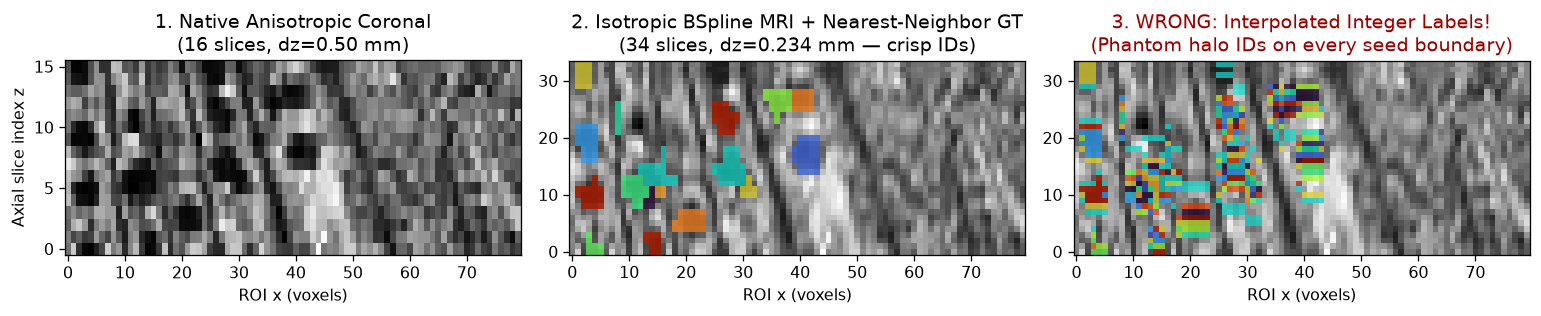

In [2]:
ROI_BOUNDS = silver_meta["roi_bounds_voxel_xyz"]  # x=[128, 208), y=[128, 208), z=[56, 72)
RX0, RX1 = ROI_BOUNDS["x"]
RY0, RY1 = ROI_BOUNDS["y"]
RZ0, RZ1 = ROI_BOUNDS["z"]

roi_img_native = vol_native[RX0:RX1, RY0:RY1, RZ0:RZ1].copy()
roi_lbl_silver_native = silver_vol_native[RX0:RX1, RY0:RY1, RZ0:RZ1].copy()

def sitk_resample_roi(arr_xyz: np.ndarray, in_spacing: tuple, out_spacing: tuple, is_label: bool) -> np.ndarray:
    """Resample a 3D (X, Y, Z) array in physical mm space using SimpleITK."""
    # SimpleITK expects array axis order (Z, Y, X) while SetSpacing uses (dx, dy, dz)
    arr_zyx = np.transpose(arr_xyz, (2, 1, 0))
    s_img = sitk.GetImageFromArray(arr_zyx.astype(np.uint16 if is_label else np.float32))
    s_img.SetSpacing(in_spacing)

    in_size = s_img.GetSize()
    out_size = [int(round(in_size[d] * (in_spacing[d] / out_spacing[d]))) for d in range(3)]

    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(out_spacing)
    resampler.SetSize(out_size)
    resampler.SetOutputDirection(s_img.GetDirection())
    resampler.SetOutputOrigin(s_img.GetOrigin())
    resampler.SetDefaultPixelValue(0)
    resampler.SetInterpolator(sitk.sitkNearestNeighbor if is_label else sitk.sitkBSpline)

    out_zyx = sitk.GetArrayFromImage(resampler.Execute(s_img))
    return np.transpose(out_zyx, (2, 1, 0))

ISO_SPACING = (spacing_native[0], spacing_native[1], spacing_native[0])  # (0.234375, 0.234375, 0.234375) mm
roi_img_iso = sitk_resample_roi(roi_img_native, spacing_native, ISO_SPACING, is_label=False)
roi_lbl_silver_iso = sitk_resample_roi(roi_lbl_silver_native, spacing_native, ISO_SPACING, is_label=True)

# Demonstrate why linear interpolation on integer labels is a bug:
wrong_linear_lbl = sitk_resample_roi(
    roi_lbl_silver_native.astype(np.float32), spacing_native, ISO_SPACING, is_label=False
)
wrong_ids = len(np.unique( np.round(np.clip(wrong_linear_lbl, 0, None)).astype(int) )) - 1
true_ids = len(np.unique(roi_lbl_silver_iso)) - 1

print(f"Native anisotropic ROI : shape={roi_img_native.shape}, spacing={spacing_native} mm")
print(f"Isotropic resampled ROI: shape={roi_img_iso.shape}, spacing={tuple(round(s, 4) for s in ISO_SPACING)} mm")
print(f"Unique label IDs after Nearest-Neighbor (correct): {true_ids} | after BSpline rounding (corrupted!): {wrong_ids}")

# Visual comparison in Coronal cross-section (y = 40 in ROI -> global y = 168)
y_loc = 40
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
axes[0].imshow(roi_img_native[:, y_loc, :].T, cmap="gray", origin="lower", aspect=spacing_native[2] / spacing_native[0])
axes[0].set_title("1. Native Anisotropic Coronal\n(16 slices, dz=0.50 mm)")

axes[1].imshow(roi_img_iso[:, y_loc, :].T, cmap="gray", origin="lower", aspect=1.0)
ov_iso = np.ma.masked_where(roi_lbl_silver_iso[:, y_loc, :].T == 0, ((roi_lbl_silver_iso[:, y_loc, :].T * 7) % 23) + 1)
axes[1].imshow(ov_iso, cmap="turbo", alpha=0.75, origin="lower", vmin=1, vmax=24)
axes[1].set_title("2. Isotropic BSpline MRI + Nearest-Neighbor GT\n(34 slices, dz=0.234 mm — crisp IDs)")

axes[2].imshow(roi_img_iso[:, y_loc, :].T, cmap="gray", origin="lower", aspect=1.0)
bad_slice = np.round(np.clip(wrong_linear_lbl[:, y_loc, :].T, 0, None)).astype(int)
ov_bad = np.ma.masked_where(bad_slice == 0, ((bad_slice * 7) % 23) + 1)
axes[2].imshow(ov_bad, cmap="turbo", alpha=0.75, origin="lower", vmin=1, vmax=24)
axes[2].set_title("3. WRONG: Interpolated Integer Labels!\n(Phantom halo IDs on every seed boundary)", color="#990000")

for ax in axes:
    ax.set_xlabel("ROI x (voxels)")
axes[0].set_ylabel("Axial slice index z")
plt.tight_layout()
plt.show()

---

## Step 2 — Interactive 3D Tri-Planar Seed Delineator (`ipywidgets` + `ipympl`)

### How to Use the Interactive Editor
1. **Pick a Rater ID & Template:** Enter your identifier (e.g., `alice`, `bob`, or `group1_raterA`) and choose one of the **4 starting templates**:
   - `Silver Micro-GT (Native 80×80×16)` *(Recommended for 5–10 min "Silver → Gold" audit & editing)*
   - `Blank Canvas (Native 80×80×16)` *(De-novo manual delineation on scanner slices)*
   - `Silver Micro-GT (Isotropic 80×80×34)` *(Smooth 3D isotropic editing; resamples back with Nearest-Neighbor on save)*
   - `Blank Canvas (Isotropic 80×80×34)`
2. **Choose a Click Tool Mode** and click directly inside **any of the 3 orthogonal views** (Axial, Coronal, or Sagittal):
   - `Inspect / Crosshair`: Moves the 3D crosshair `(x, y, z)` and prints voxel intensity + 3D `Seed ID` volume (`mm³`).
   - `3D Seed Stamp (Auto-Grow)`: **Fastest way to add a missed seed!** Click the dark center of an unlabeled seed to grow a local 3D dark ovoid region with a fresh `Seed ID`.
   - `Paint Brush`: Paints voxels with `Active ID` (use **New Seed ID** before painting a new seed; toggle **3D Brush** to paint `±1` adjacent slice too).
   - `Erase Brush`: Clears voxels to background (`0`) within `Brush Radius`.
   - `Delete Instance`: 1-click removes the entire 3D connected `Seed ID` you clicked (ideal for deleting a false-positive septum crease).
   - `Split Merged Pair`: Splits a fused 2-seed cluster under your click into two separate 3D `Seed ID`s via physical-mm K-means.
3. **Save Locally (`MyStuff/`):** Click **Save NIfTI + JSON** to export a full-grid `256 × 256 × 128` `uint16` NIfTI file (`MyStuff/kiwi-gt/kiwi_gt_<rater>.nii.gz`) that works directly in **Step 3**, **Step 4**, **Notebook `03`**, **ITK-SNAP**, and **3D Slicer**!

In [3]:
class KiwiSeedEditor3D:
    """Interactive 3-plane 3D NIfTI seed delineator & template editor using ipywidgets + matplotlib."""

    TEMPLATES = {
        "Silver Micro-GT (Native 80×80×16)": ("native", True),
        "Blank Canvas (Native 80×80×16)": ("native", False),
        "Silver Micro-GT (Isotropic 80×80×34)": ("isotropic", True),
        "Blank Canvas (Isotropic 80×80×34)": ("isotropic", False),
    }

    def __init__(self):
        self.undo_stack = []
        self.edit_history = []
        self.grid_mode = "native"
        self._load_template("Silver Micro-GT (Native 80×80×16)", reset_history=True)
        self._build_widgets()

    def _load_template(self, template_label: str, reset_history: bool = True):
        grid_mode, use_silver = self.TEMPLATES[template_label]
        self.grid_mode = grid_mode
        self.template_label = template_label
        if grid_mode == "native":
            self.img = roi_img_native.copy()
            self.spacing = spacing_native
            base_lbl = roi_lbl_silver_native if use_silver else np.zeros_like(roi_lbl_silver_native)
        else:
            self.img = roi_img_iso.copy()
            self.spacing = ISO_SPACING
            base_lbl = roi_lbl_silver_iso if use_silver else np.zeros_like(roi_lbl_silver_iso)

        self.vox_vol = float(np.prod(self.spacing))
        self.labels = base_lbl.astype(np.uint16).copy()
        self.cx = self.img.shape[0] // 2
        self.cy = self.img.shape[1] // 2
        self.cz = self.img.shape[2] // 2
        self.active_id = int(self.labels.max()) + 1
        if reset_history:
            self.undo_stack = []
            self.edit_history = [{"action": "load_template", "template": template_label}]

    def _push_undo(self):
        self.undo_stack.append(self.labels.copy())
        if len(self.undo_stack) > 15:
            self.undo_stack.pop(0)

    def _seed_count_and_vol(self) -> tuple[int, float]:
        ids = np.unique(self.labels)
        n_seeds = int(len(ids) - (1 if 0 in ids else 0))
        tot_mm3 = float((self.labels > 0).sum() * self.vox_vol)
        return n_seeds, tot_mm3

    def apply_action_at(self, x: int, y: int, z: int, mode: str, radius_px: int = 2, brush_3d: bool = False) -> str:
        nx, ny, nz = self.img.shape
        x = int(np.clip(x, 0, nx - 1))
        y = int(np.clip(y, 0, ny - 1))
        z = int(np.clip(z, 0, nz - 1))
        self.cx, self.cy, self.cz = x, y, z

        clicked_id = int(self.labels[x, y, z])
        val = float(self.img[x, y, z])

        if mode == "Inspect / Crosshair":
            if clicked_id > 0:
                inst_mm3 = float((self.labels == clicked_id).sum() * self.vox_vol)
                return f"Crosshair ({x}, {y}, {z}) | MRI={val:.0f} | Seed ID #{clicked_id} ({inst_mm3:.2f} mm³)"
            return f"Crosshair ({x}, {y}, {z}) | MRI={val:.0f} | Background (0)"

        if mode == "3D Seed Stamp (Auto-Grow)":
            self._push_undo()
            rx_mm, rz_mm = 0.68, 1.15
            rx = int(np.ceil(rx_mm / self.spacing[0]))
            ry = int(np.ceil(rx_mm / self.spacing[1]))
            rz = int(np.ceil(rz_mm / self.spacing[2]))
            x0, x1 = max(0, x - rx), min(nx, x + rx + 1)
            y0, y1 = max(0, y - ry), min(ny, y + ry + 1)
            z0, z1 = max(0, z - rz), min(nz, z + rz + 1)
            xx, yy, zz = np.ogrid[x0 - x : x1 - x, y0 - y : y1 - y, z0 - z : z1 - z]
            ellip = ((xx * self.spacing[0] / rx_mm) ** 2 + (yy * self.spacing[1] / rx_mm) ** 2 + (zz * self.spacing[2] / rz_mm) ** 2) <= 1.0
            patch = self.img[x0:x1, y0:y1, z0:z1]
            local_hi = float(np.percentile(patch, 85))
            thr = max(val * 1.45, val + 0.35 * max(local_hi - val, 500.0))
            dark_cand = ellip & (patch <= thr)
            cc, _ = ndi.label(dark_cand)
            center_cc = cc[x - x0, y - y0, z - z0]
            stamp_mask = (cc == center_cc) if center_cc > 0 else (
                ((xx * self.spacing[0] / 0.40) ** 2 + (yy * self.spacing[1] / 0.40) ** 2 + (zz * self.spacing[2] / 0.75) ** 2) <= 1.0
            )
            new_id = int(self.labels.max()) + 1
            sub_lbl = self.labels[x0:x1, y0:y1, z0:z1]
            sub_lbl[stamp_mask & (sub_lbl == 0)] = new_id
            self.active_id = new_id + 1
            self.edit_history.append({"action": "stamp_seed", "xyz": [x, y, z], "id": new_id})
            return f"Stamped new 3D Seed ID #{new_id} ({int(stamp_mask.sum())} voxels) at ({x}, {y}, {z})"

        if mode in ("Paint Brush", "Erase Brush"):
            self._push_undo()
            dz_lim = 1 if brush_3d else 0
            x0, x1 = max(0, x - radius_px), min(nx, x + radius_px + 1)
            y0, y1 = max(0, y - radius_px), min(ny, y + radius_px + 1)
            z0, z1 = max(0, z - dz_lim), min(nz, z + dz_lim + 1)
            xx, yy, zz = np.ogrid[x0 - x : x1 - x, y0 - y : y1 - y, z0 - z : z1 - z]
            disk_mask = (xx**2 + yy**2 <= radius_px**2) & (np.abs(zz) <= dz_lim)
            target_val = int(self.active_id) if mode == "Paint Brush" else 0
            self.labels[x0:x1, y0:y1, z0:z1][disk_mask] = target_val
            self.edit_history.append({"action": mode, "xyz": [x, y, z], "id": target_val})
            return f"{mode}: wrote ID {target_val} at ({x}, {y}, {z})"

        if mode == "Delete Instance":
            if clicked_id == 0:
                return f"No seed label at ({x}, {y}, {z}) to delete."
            self._push_undo()
            n_rm = int((self.labels == clicked_id).sum())
            self.labels[self.labels == clicked_id] = 0
            self.edit_history.append({"action": "delete_instance", "id": clicked_id})
            return f"Deleted Seed ID #{clicked_id} ({n_rm} voxels)"

        if mode == "Split Merged Pair":
            if clicked_id == 0:
                return f"Click on a labeled seed cluster to split it."
            coords = np.argwhere(self.labels == clicked_id)
            if len(coords) < 10:
                return f"Seed ID #{clicked_id} is too small ({len(coords)} voxels) to split."
            self._push_undo()
            phys = coords * np.array(self.spacing)
            km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(phys)
            new_id = int(self.labels.max()) + 1
            c2 = coords[km.labels_ == 1]
            self.labels[c2[:, 0], c2[:, 1], c2[:, 2]] = new_id
            self.active_id = new_id + 1
            self.edit_history.append({"action": "split_instance", "old_id": clicked_id, "new_id": new_id})
            return f"Split Seed ID #{clicked_id} into #{clicked_id} and #{new_id}"

        return "Ready."

    def export_full_native_nifti(self, rater_id: str) -> tuple[Path, Path]:
        clean_rater = "".join(ch if (ch.isalnum() or ch in "-_") else "_" for ch in rater_id.strip()) or "anon"
        if self.grid_mode == "native":
            roi_native_out = self.labels.astype(np.uint16)
        else:
            roi_native_out = sitk_resample_roi(self.labels, ISO_SPACING, spacing_native, is_label=True).astype(np.uint16)

        full_vol = np.zeros(vol_native.shape, dtype=np.uint16)
        full_vol[RX0:RX1, RY0:RY1, RZ0:RZ1] = roi_native_out
        out_nii = mystuff_dir / f"kiwi_gt_{clean_rater}.nii.gz"
        hdr = nii_img.header.copy()
        hdr.set_data_dtype(np.uint16)
        nib.save(nib.Nifti1Image(full_vol, nii_img.affine, hdr), str(out_nii))

        ids = np.unique(roi_native_out)
        n_seeds = int(len(ids) - (1 if 0 in ids else 0))
        out_json = mystuff_dir / f"kiwi_gt_{clean_rater}.json"
        meta_out = {
            "rater_id": clean_rater,
            "timestamp": datetime.now().isoformat(timespec="seconds"),
            "starting_template": self.template_label,
            "edited_grid_mode": self.grid_mode,
            "roi_bounds_voxel_xyz": ROI_BOUNDS,
            "n_seeds_in_roi": n_seeds,
            "total_seed_vol_mm3": round(float((roi_native_out > 0).sum() * np.prod(spacing_native)), 3),
            "n_edits_logged": len(self.edit_history) - 1,
            "edit_history": self.edit_history[-50:],
        }
        out_json.write_text(json.dumps(meta_out, indent=2) + "\n", encoding="utf-8")
        return out_nii, out_json

    def _build_widgets(self):
        self.w_rater = widgets.Text(value="rater_demo", description="Rater ID:", layout=widgets.Layout(width="210px"))
        self.w_tmpl = widgets.Dropdown(
            options=list(self.TEMPLATES.keys()),
            value=self.template_label,
            description="Template:",
            layout=widgets.Layout(width="340px"),
        )
        self.w_mode = widgets.ToggleButtons(
            options=[
                "Inspect / Crosshair",
                "3D Seed Stamp (Auto-Grow)",
                "Paint Brush",
                "Erase Brush",
                "Delete Instance",
                "Split Merged Pair",
            ],
            value="Inspect / Crosshair",
            description="Click Tool:",
            style={"button_width": "auto"},
        )
        self.w_x = widgets.IntSlider(value=self.cx, min=0, max=self.img.shape[0] - 1, description="ROI x:")
        self.w_y = widgets.IntSlider(value=self.cy, min=0, max=self.img.shape[1] - 1, description="ROI y:")
        self.w_z = widgets.IntSlider(value=self.cz, min=0, max=self.img.shape[2] - 1, description="ROI z:")
        self.w_alpha = widgets.FloatSlider(value=0.68, min=0.0, max=1.0, step=0.05, description="Mask α:")
        self.w_radius = widgets.IntSlider(value=2, min=1, max=5, description="Brush px:")
        self.w_3d = widgets.Checkbox(value=False, description="3D Brush (±1 z)", indent=False)
        self.w_id = widgets.BoundedIntText(value=self.active_id, min=1, max=65000, description="Active ID:", layout=widgets.Layout(width="155px"))
        self.btn_apply = widgets.Button(description="Apply at Crosshair", button_style="primary", layout=widgets.Layout(width="155px"))
        self.btn_new_id = widgets.Button(description="New Seed ID", button_style="info")
        self.btn_undo = widgets.Button(description="Undo", button_style="warning")
        self.btn_save = widgets.Button(description="Save NIfTI + JSON (MyStuff)", button_style="success", layout=widgets.Layout(width="230px"))
        self.btn_colab_dl = widgets.Button(description="Download in Browser (Colab)", layout=widgets.Layout(width="210px"))
        self.w_status = widgets.HTML(value="")
        self.out_canvas = widgets.Output()

        self.w_tmpl.observe(self._on_template_change, names="value")
        for w in (self.w_x, self.w_y, self.w_z, self.w_alpha):
            w.observe(self._on_view_change, names="value")
        self.w_id.observe(self._on_id_change, names="value")
        self.btn_apply.on_click(self._on_apply_crosshair)
        self.btn_new_id.on_click(self._on_new_id)
        self.btn_undo.on_click(self._on_undo)
        self.btn_save.on_click(self._on_save)
        self.btn_colab_dl.on_click(self._on_colab_dl)

        self._update_status("Interactive 3D workspace ready — use sliders + 'Apply at Crosshair' (or '%matplotlib widget' to click views).")

    def _update_status(self, msg: str):
        n_s, v_mm3 = self._seed_count_and_vol()
        self.w_status.value = (
            f"<b>Status:</b> {msg} &nbsp;|&nbsp; "
            f"<b>ROI Seeds:</b> {n_s} ({v_mm3:.1f} mm³) &nbsp;|&nbsp; "
            f"<b>Grid:</b> <code>{self.grid_mode}</code> {self.img.shape}"
        )

    def _on_template_change(self, change):
        self._load_template(change["new"], reset_history=True)
        self.w_z.max = self.img.shape[2] - 1
        self.w_x.value, self.w_y.value, self.w_z.value = self.cx, self.cy, self.cz
        self.w_id.value = self.active_id
        self._update_status(f"Loaded template: {change['new']}")
        self.redraw()

    def _on_id_change(self, change):
        self.active_id = int(change["new"])

    def _on_apply_crosshair(self, _):
        msg = self.apply_action_at(
            self.cx, self.cy, self.cz,
            mode=self.w_mode.value,
            radius_px=int(self.w_radius.value),
            brush_3d=bool(self.w_3d.value),
        )
        self.w_id.value = self.active_id
        self._update_status(msg)
        self.redraw()

    def _on_new_id(self, _):
        self.active_id = int(self.labels.max()) + 1
        self.w_id.value = self.active_id
        self._update_status(f"Selected fresh Seed ID #{self.active_id}")

    def _on_undo(self, _):
        if not self.undo_stack:
            self._update_status("Nothing left to undo.")
            return
        self.labels = self.undo_stack.pop()
        self._update_status("Reverted last edit.")
        self.redraw()

    def _on_save(self, _):
        out_nii, out_json = self.export_full_native_nifti(self.w_rater.value)
        self._update_status(f"Saved <code>{out_nii.name}</code> &amp; <code>{out_json.name}</code> to <code>MyStuff/kiwi-gt/</code>!")

    def _on_colab_dl(self, _):
        out_nii, _ = self.export_full_native_nifti(self.w_rater.value)
        if IN_COLAB:
            from google.colab import files
            files.download(str(out_nii))
            self._update_status(f"Triggered browser download of {out_nii.name}")
        else:
            self._update_status(f"Saved locally at <code>{out_nii}</code> (browser download is only needed in Colab).")

    def _on_view_change(self, _):
        self.cx, self.cy, self.cz = int(self.w_x.value), int(self.w_y.value), int(self.w_z.value)
        self.redraw()

    def _on_mpl_click(self, event):
        if event.inaxes is None or event.xdata is None or event.ydata is None:
            return
        ix, iy = int(round(event.xdata)), int(round(event.ydata))
        if event.inaxes == self.ax_ax:
            x, y, z = ix, iy, self.cz
        elif event.inaxes == self.ax_co:
            x, y, z = ix, self.cy, iy
        elif event.inaxes == self.ax_sa:
            x, y, z = self.cx, ix, iy
        else:
            return
        msg = self.apply_action_at(
            x, y, z,
            mode=self.w_mode.value,
            radius_px=int(self.w_radius.value),
            brush_3d=bool(self.w_3d.value),
        )
        self.w_id.value = self.active_id
        self.w_x.value, self.w_y.value, self.w_z.value = self.cx, self.cy, self.cz
        self._update_status(msg)
        self.redraw()

    def render_figure(self, fig=None):
        if fig is None:
            fig, (self.ax_ax, self.ax_co, self.ax_sa) = plt.subplots(1, 3, figsize=(13.2, 4.2))
        else:
            fig.clf()
            self.ax_ax, self.ax_co, self.ax_sa = fig.subplots(1, 3)

        vmax = float(np.percentile(self.img, 99.2))
        alpha = float(self.w_alpha.value)
        asp_z = self.spacing[2] / self.spacing[0]

        # 1. Axial (x, y) at cz
        sl_ax = self.img[:, :, self.cz].T
        lb_ax = self.labels[:, :, self.cz].T
        self.ax_ax.imshow(sl_ax, cmap="gray", origin="lower", vmin=0, vmax=vmax)
        if alpha > 0:
            ov = np.ma.masked_where(lb_ax == 0, ((lb_ax * 7) % 23) + 1)
            self.ax_ax.imshow(ov, cmap="turbo", alpha=alpha, origin="lower", vmin=1, vmax=24)
        self.ax_ax.axvline(self.cx, color="yellow", lw=0.8, ls="--")
        self.ax_ax.axhline(self.cy, color="yellow", lw=0.8, ls="--")
        self.ax_ax.set_title(f"Axial (ROI z={self.cz} | global z={RZ0 + int(round(self.cz * self.spacing[2] / spacing_native[2]))})")
        self.ax_ax.set_xlabel("ROI x")
        self.ax_ax.set_ylabel("ROI y")

        # 2. Coronal (x, z) at cy
        sl_co = self.img[:, self.cy, :].T
        lb_co = self.labels[:, self.cy, :].T
        self.ax_co.imshow(sl_co, cmap="gray", origin="lower", aspect=asp_z, vmin=0, vmax=vmax)
        if alpha > 0:
            ov = np.ma.masked_where(lb_co == 0, ((lb_co * 7) % 23) + 1)
            self.ax_co.imshow(ov, cmap="turbo", alpha=alpha, origin="lower", aspect=asp_z, vmin=1, vmax=24)
        self.ax_co.axvline(self.cx, color="yellow", lw=0.8, ls="--")
        self.ax_co.axhline(self.cz, color="yellow", lw=0.8, ls="--")
        self.ax_co.set_title(f"Coronal (ROI y={self.cy})")
        self.ax_co.set_xlabel("ROI x")
        self.ax_co.set_ylabel("ROI z")

        # 3. Sagittal (y, z) at cx
        sl_sa = self.img[self.cx, :, :].T
        lb_sa = self.labels[self.cx, :, :].T
        self.ax_sa.imshow(sl_sa, cmap="gray", origin="lower", aspect=asp_z, vmin=0, vmax=vmax)
        if alpha > 0:
            ov = np.ma.masked_where(lb_sa == 0, ((lb_sa * 7) % 23) + 1)
            self.ax_sa.imshow(ov, cmap="turbo", alpha=alpha, origin="lower", aspect=asp_z, vmin=1, vmax=24)
        self.ax_sa.axvline(self.cy, color="yellow", lw=0.8, ls="--")
        self.ax_sa.axhline(self.cz, color="yellow", lw=0.8, ls="--")
        self.ax_sa.set_title(f"Sagittal (ROI x={self.cx})")
        self.ax_sa.set_xlabel("ROI y")
        self.ax_sa.set_ylabel("ROI z")

        fig.tight_layout()
        return fig

    def redraw(self):
        with self.out_canvas:
            clear_output(wait=True)
            fig = self.render_figure()
            fig.canvas.mpl_connect("button_press_event", self._on_mpl_click)
            plt.show()

    def ui(self):
        row1 = widgets.HBox([self.w_rater, self.w_tmpl, self.btn_save, self.btn_colab_dl])
        row2 = self.w_mode
        row3 = widgets.HBox([self.w_x, self.w_y, self.w_z])
        row4 = widgets.HBox([self.w_alpha, self.w_radius, self.w_3d, self.w_id, self.btn_apply, self.btn_new_id, self.btn_undo])
        return widgets.VBox([row1, row2, row3, row4, self.w_status, self.out_canvas])

# Note: In live JupyterLab / Colab, uncomment `%matplotlib widget` below for direct mouse-click events on the canvas!
# %matplotlib widget

editor = KiwiSeedEditor3D()
display(editor.ui())
editor.redraw()

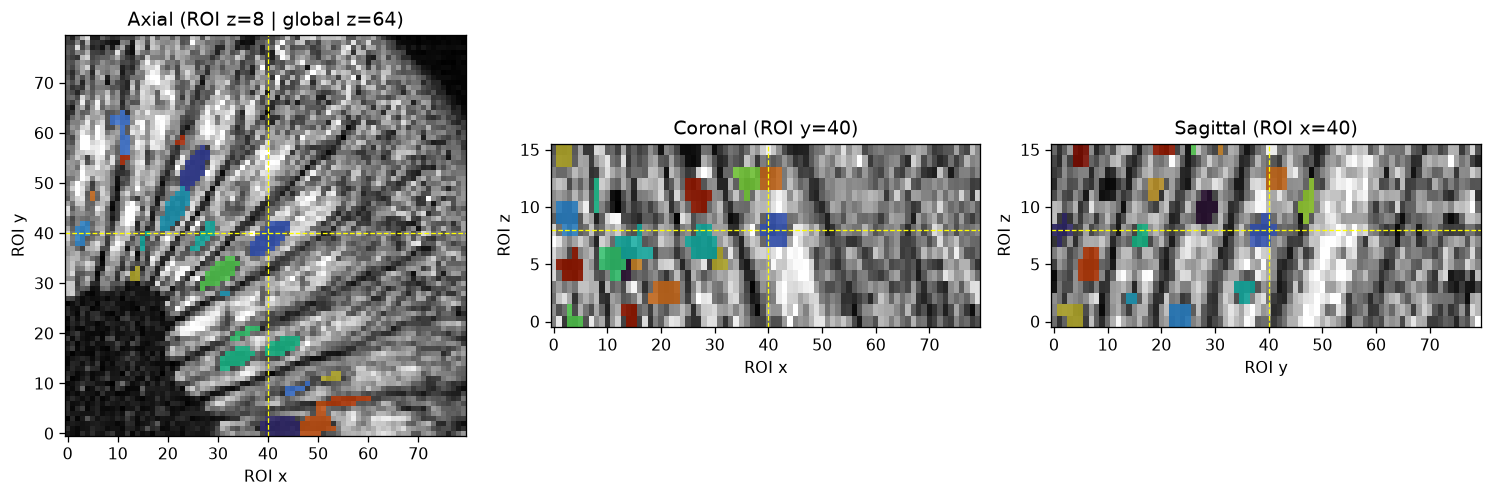

In [4]:
# Static preview snapshot of the active 3D Tri-Planar Editor (visible on GitHub / nbviewer even before running widgets)
_fig_preview = editor.render_figure()
plt.show()

---

## Step 3 — Inter-Rater Variability & Multi-Rater STAPLE Consensus

Suppose two or three students (or neuroradiologists!) independently curate the exact same `80 × 80 × 16` 3D sector and save their NIfTI masks to `MyStuff/kiwi-gt/kiwi_gt_<rater>.nii.gz`:
- **Why do careful human raters disagree?**
  1. **Boundary threshold ambiguity:** Partial-volume blurring (`dz = 0.50 mm`) makes seed borders gradual rather than step-edges — Rater A draws tight dark cores while Rater B includes the grey partial-volume rim.
  2. **Faint grazing seeds:** A seed whose center lies in `z = 64` looks tiny and grey in `z = 62` or `z = 66` — one rater marks it, another skips it.
  3. **Touching seeds in a radial chamber:** Two seeds separated by `< 0.3 mm` of gel may be labeled as `1` instance by Rater C and `2` instances by Rater A.

Below, our evaluation pipeline:
1. Automatically loads any `kiwi_gt_*.nii.gz` files you saved in `MyStuff/kiwi-gt/`!
2. If fewer than 2 personal rater files exist yet, generates a **realistic 3-rater cohort** (`Rater_A_Conservative`, `Rater_B_Sensitive`, `Rater_C_Generous`) reflecting these exact three human annotation styles on the 7T MRI sector so you can explore the full inter-rater and **STAPLE** analysis immediately.
3. Computes **pairwise Voxel Dice**, **Cohen's $\kappa$**, **Symmetric 3D Instance F1**, and **Seed Count $\Delta N$**, and runs **[Warfield, Zou & Wells (2004) STAPLE](https://pubmed.ncbi.nlm.nih.gov/15250643/)** (`SimpleITK.STAPLEImageFilter`) to jointly estimate each rater's latent **Sensitivity ($p_j$)** and **Specificity ($q_j$)** alongside a probabilistic **Consensus Ground Truth**!

In [5]:
def simulate_three_human_rater_styles(raw_roi: np.ndarray, base_silver: np.ndarray, sp=spacing_native) -> dict[str, np.ndarray]:
    """Create 3 realistic human rater styles on the ROI when <2 personal rater files exist in MyStuff."""
    rng = np.random.default_rng(2027)
    vox_mm3 = float(np.prod(sp))

    # Style 1 — Rater A (Conservative core delineator: erodes faint outer rims, skips smallest grazing tips)
    rater_a = np.zeros_like(base_silver, dtype=np.uint16)
    aid = 0
    for prop in measure.regionprops(base_silver, intensity_image=raw_roi):
        if prop.area * vox_mm3 < 0.42 or prop.intensity_min > 1850:
            continue
        coords = prop.coords
        core_keep = raw_roi[coords[:, 0], coords[:, 1], coords[:, 2]] <= np.percentile(
            raw_roi[coords[:, 0], coords[:, 1], coords[:, 2]], 82
        )
        kept = coords[core_keep] if core_keep.sum() >= 6 else coords
        aid += 1
        rater_a[kept[:, 0], kept[:, 1], kept[:, 2]] = aid

    # Style 2 — Rater B (Sensitive partial-volume rater: keeps all silver seeds + stamps 7 faint dark tips)
    rater_b = base_silver.copy().astype(np.uint16)
    sm = ndi.gaussian_filter(raw_roi, sigma=(0.8, 0.8, 0.6))
    faint_cands = np.argwhere((rater_b == 0) & (raw_roi < 3400) & (sm > 4200) & (sm < 10500))
    next_id = int(rater_b.max()) + 1
    added = 0
    for idx in rng.permutation(len(faint_cands)):
        cx, cy, cz = faint_cands[idx]
        if not (6 <= cx < raw_roi.shape[0] - 6 and 6 <= cy < raw_roi.shape[1] - 6 and 2 <= cz < raw_roi.shape[2] - 2):
            continue
        if (rater_b[cx - 3 : cx + 4, cy - 3 : cy + 4, cz - 1 : cz + 2] > 0).any():
            continue
        rater_b[cx - 1 : cx + 2, cy - 1 : cy + 2, cz : cz + 2] = next_id
        next_id += 1
        added += 1
        if added == 7:
            break

    # Style 3 — Rater C (Boundary-generous rater: 1-px in-plane dilation into dark rim, occasionally merging close neighbors)
    rater_c_bin = np.zeros_like(base_silver, dtype=bool)
    selem = morphology.disk(1)
    for z in range(base_silver.shape[2]):
        dil = ndi.binary_dilation(base_silver[:, :, z] > 0, structure=selem)
        rater_c_bin[:, :, z] = (base_silver[:, :, z] > 0) | (dil & (raw_roi[:, :, z] < 6800))
    rater_c, _ = ndi.label(rater_c_bin)
    return {
        "Rater_A (Conservative)": rater_a.astype(np.uint16),
        "Rater_B (Sensitive)": rater_b.astype(np.uint16),
        "Rater_C (Generous Rim)": rater_c.astype(np.uint16),
    }


def instance_f1_symmetric(lbl_1: np.ndarray, lbl_2: np.ndarray, min_iou: float = 0.25) -> float:
    """Compute 3D instance-level F1 between two ROI instance masks using greedy IoU >= 0.25 matching."""
    p1 = measure.regionprops(lbl_1)
    p2 = measure.regionprops(lbl_2)
    if not p1 and not p2:
        return 1.0
    if not p1 or not p2:
        return 0.0
    matched_2 = set()
    tp = 0
    for a in p1:
        ca = a.coords
        ov_ids = lbl_2[ca[:, 0], ca[:, 1], ca[:, 2]]
        ov_ids = ov_ids[ov_ids > 0]
        if len(ov_ids) == 0:
            continue
        vals, cnts = np.unique(ov_ids, return_counts=True)
        order = np.argsort(-cnts)
        for idx in order:
            bid, inter = int(vals[idx]), int(cnts[idx])
            if bid in matched_2:
                continue
            b_area = int((lbl_2 == bid).sum())
            iou = inter / float(a.area + b_area - inter)
            if iou >= min_iou:
                tp += 1
                matched_2.add(bid)
                break
    return 2.0 * tp / float(len(p1) + len(p2))


# Load saved personal NIfTI files from MyStuff/kiwi-gt if >= 2 exist; otherwise include simulated 3-rater cohort
saved_niis = sorted(mystuff_dir.glob("kiwi_gt_*.nii.gz"))
rater_rois: dict[str, np.ndarray] = {}
for p in saved_niis:
    arr = np.asarray(nib.load(str(p)).dataobj, dtype=np.uint16)
    rater_rois[p.stem.replace(".nii", "").replace("kiwi_gt_", "User_")] = arr[RX0:RX1, RY0:RY1, RZ0:RZ1]

if len(rater_rois) < 2:
    print(f"Found {len(rater_rois)} saved personal rater file(s) in MyStuff/kiwi-gt/ — adding 3-rater benchmark cohort:")
    rater_rois.update(simulate_three_human_rater_styles(roi_img_native, roi_lbl_silver_native))
else:
    print(f"Loaded {len(rater_rois)} personal rater segmentations from {mystuff_dir}!")

# 1. Per-rater summary
rater_rows = []
for name, r_lbl in rater_rois.items():
    ids = np.unique(r_lbl)
    n_s = int(len(ids) - (1 if 0 in ids else 0))
    fg_vox = int((r_lbl > 0).sum())
    vols = np.bincount(r_lbl.ravel())[1:]
    vols = vols[vols > 0] * float(np.prod(spacing_native))
    rater_rows.append({
        "Rater": name,
        "3D Seed Count (ROI)": n_s,
        "Foreground Voxels": fg_vox,
        "Total Seed Vol (mm³)": round(fg_vox * float(np.prod(spacing_native)), 2),
        "Median Single-Seed Vol (mm³)": round(float(np.median(vols)) if len(vols) else 0.0, 2),
    })
display(pd.DataFrame(rater_rows).set_index("Rater"))

# 2. Pairwise Inter-Rater Variability Table
names = list(rater_rois.keys())
pair_rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        n1, n2 = names[i], names[j]
        l1, l2 = rater_rois[n1], rater_rois[n2]
        b1, b2 = (l1 > 0).ravel(), (l2 > 0).ravel()
        inter = int((b1 & b2).sum())
        dice = (2.0 * inter) / max(int(b1.sum() + b2.sum()), 1)
        kappa = float(cohen_kappa_score(b1, b2))
        inst_f1 = instance_f1_symmetric(l1, l2)
        c1 = len(np.unique(l1)) - (1 if 0 in l1 else 0)
        c2 = len(np.unique(l2)) - (1 if 0 in l2 else 0)
        pair_rows.append({
            "Rater Pair": f"{n1}  vs.  {n2}",
            "Voxel Dice": round(dice, 3),
            "Cohen's κ": round(kappa, 3),
            "3D Instance F1": round(inst_f1, 3),
            "Count Diff (|ΔN|)": f"{abs(c1 - c2)} ({c1} vs {c2})",
        })
print("\nPairwise Human Inter-Rater Agreement:")
display(pd.DataFrame(pair_rows).set_index("Rater Pair"))

Found 0 saved personal rater file(s) in MyStuff/kiwi-gt/ — adding 3-rater benchmark cohort:


,3D Seed Count (ROI),Foreground Voxels,Total Seed Vol (mm³),Median Single-Seed Vol (mm³)
Rater,,,,
Rater_A (Conservative),82,3598,98.82,1.26
Rater_B (Sensitive),105,4805,131.97,1.43
Rater_C (Generous Rim),62,5293,145.38,1.74



Pairwise Human Inter-Rater Agreement:


,Voxel Dice,Cohen's κ,3D Instance F1,Count Diff (|ΔN|)
Rater Pair,,,,
Rater_A (Conservative) vs. Rater_B (Sensitive),0.856,0.850,0.877,23 (82 vs 105)
Rater_A (Conservative) vs. Rater_C (Generous Rim),0.809,0.801,0.681,20 (82 vs 62)
Rater_B (Sensitive) vs. Rater_C (Generous Rim),0.927,0.923,0.707,43 (105 vs 62)


STAPLE Latent Rater Performance Estimates (Expectation–Maximization):


,STAPLE Sensitivity (p_j),STAPLE Specificity (q_j)
Rater,,
Rater_A (Conservative),0.769,1.0000
Rater_B (Sensitive),1.000,0.9987
Rater_C (Generous Rim),1.000,0.9937


Consensus ROI foreground: Majority-Vote = 4,679 voxels | STAPLE (P>=0.5) = 4,679 voxels (85 3D seed instances)


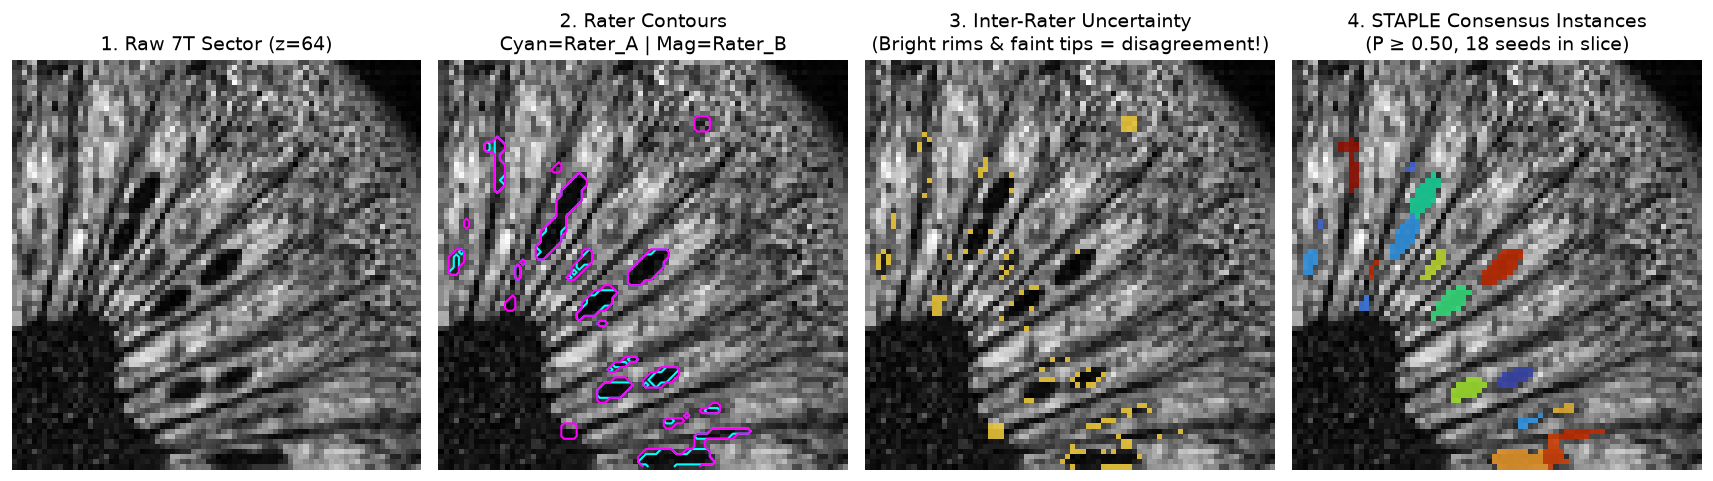

In [6]:
# 3. Multi-Rater Consensus via SimpleITK STAPLE vs. Majority Vote
sitk_masks = [
    sitk.GetImageFromArray(np.transpose((lbl > 0).astype(np.uint8), (2, 1, 0)))
    for lbl in rater_rois.values()
]
staple_filter = sitk.STAPLEImageFilter()
staple_filter.SetForegroundValue(1)
staple_prob_sitk = staple_filter.Execute(sitk_masks)
staple_prob = np.transpose(sitk.GetArrayFromImage(staple_prob_sitk), (2, 1, 0))  # P(true seed | raters) in [0, 1]
staple_bin = staple_prob >= 0.50

vote_fraction = np.mean([(lbl > 0).astype(np.float32) for lbl in rater_rois.values()], axis=0)
majority_bin = vote_fraction >= 0.50

def build_ellip(rx_mm, rz_mm, sp=spacing_native):
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])), int(np.ceil(rx_mm / sp[1])), int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0

# Split touching seeds inside STAPLE binary consensus using physical distance watershed so it yields 3D instances!
dist_st = ndi.distance_transform_edt(staple_bin, sampling=spacing_native)
dist_sm = ndi.gaussian_filter(dist_st, sigma=(0.24 / spacing_native[0], 0.24 / spacing_native[1], 0.30 / spacing_native[2]))
pk_fp = build_ellip(0.72, 1.05, sp=spacing_native)
st_markers, _ = ndi.label((dist_sm == ndi.maximum_filter(dist_sm, footprint=pk_fp)) & staple_bin & (dist_st >= 0.20))
staple_instances = segmentation.watershed(-dist_sm, markers=st_markers, mask=staple_bin).astype(np.uint16)

sens_vec = staple_filter.GetSensitivity()
spec_vec = staple_filter.GetSpecificity()
staple_perf = []
for idx, r_name in enumerate(rater_rois.keys()):
    staple_perf.append({
        "Rater": r_name,
        "STAPLE Sensitivity (p_j)": round(float(sens_vec[idx]), 3),
        "STAPLE Specificity (q_j)": round(float(spec_vec[idx]), 4),
    })
print("STAPLE Latent Rater Performance Estimates (Expectation–Maximization):")
display(pd.DataFrame(staple_perf).set_index("Rater"))
print(
    f"Consensus ROI foreground: Majority-Vote = {int(majority_bin.sum()):,} voxels | "
    f"STAPLE (P>=0.5) = {int(staple_bin.sum()):,} voxels ({int(staple_instances.max())} 3D seed instances)"
)

# Visual 4-panel comparison on central slice z_roi = 8 (global z = 64)
z_loc = 8
fig, axes = plt.subplots(1, 4, figsize=(15.0, 4.1))
raw_sl = roi_img_native[:, :, z_loc].T

axes[0].imshow(raw_sl, cmap="gray", origin="lower")
axes[0].set_title("1. Raw 7T Sector (z=64)")

r_first_two = list(rater_rois.items())[:2]
axes[1].imshow(raw_sl, cmap="gray", origin="lower")
axes[1].contour((r_first_two[0][1][:, :, z_loc].T > 0), levels=[0.5], colors="cyan", linewidths=1.3)
axes[1].contour((r_first_two[1][1][:, :, z_loc].T > 0), levels=[0.5], colors="magenta", linewidths=1.3)
axes[1].set_title(f"2. Rater Contours\nCyan={r_first_two[0][0].split()[0]} | Mag={r_first_two[1][0].split()[0]}")

# Disagreement / Uncertainty map: p * (1 - p) peaks where raters disagree!
disagree_map = vote_fraction[:, :, z_loc].T * (1.0 - vote_fraction[:, :, z_loc].T) * 4.0
axes[2].imshow(raw_sl, cmap="gray", origin="lower")
im_u = axes[2].imshow(np.ma.masked_where(disagree_map < 0.01, disagree_map), cmap="inferno", alpha=0.85, origin="lower", vmin=0, vmax=1)
axes[2].set_title("3. Inter-Rater Uncertainty\n(Bright rims & faint tips = disagreement!)")

axes[3].imshow(raw_sl, cmap="gray", origin="lower")
ov_st = np.ma.masked_where(staple_instances[:, :, z_loc].T == 0, ((staple_instances[:, :, z_loc].T * 7) % 23) + 1)
axes[3].imshow(ov_st, cmap="turbo", alpha=0.80, origin="lower", vmin=1, vmax=24)
axes[3].set_title(f"4. STAPLE Consensus Instances\n(P ≥ 0.50, {len(np.unique(staple_instances[:, :, z_loc])) - 1} seeds in slice)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

---

## Step 4 — Personalized Ground-Truth Benchmark: How Much Does the Reference Shift Algorithm Scores?

Finally, let us run **Rung 2B (`3D Anisotropic Top-Hat + Watershed`)** from [`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb) and evaluate the **exact same algorithm prediction** against:
1. Each individual rater in `rater_rois` (including your own saved `MyStuff/kiwi-gt/kiwi_gt_<rater>.nii.gz` file once saved in Step 2!)
2. The original **Silver-Standard Micro-GT** (`kiwi_micro_gt_labels.nii.gz`)
3. The **Multi-Rater STAPLE Consensus** mask!

Watch how **Precision, Recall, F1, and the bias-calibrated whole-fruit seed count ($\hat{N}_{\text{cal}} = \hat{N}_{\text{raw}} \cdot \text{P} / \text{R}$)** shift across reference standards — demonstrating why reporting **inter-rater bounds alongside algorithm metrics** is essential in biomedical imaging research!

In [7]:
def build_ellip(rx_mm, rz_mm, sp=spacing_native):
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])), int(np.ceil(rx_mm / sp[1])), int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0

# Whole-fruit interior mask + Rung 2B prediction (identical to Notebook 03)
v_sm = ndi.gaussian_filter(vol_native, sigma=(1.2 / spacing_native[0], 1.2 / spacing_native[1], 1.2 / spacing_native[2]))
fg_r = v_sm > (filters.threshold_otsu(v_sm[::2, ::2, ::2]) * 0.35)
fg_f = np.zeros_like(fg_r)
for z in range(vol_native.shape[2]):
    fg_f[:, :, z] = ndi.binary_fill_holes(fg_r[:, :, z])
fg_f = ndi.binary_fill_holes(fg_f)
lbl_fg, _ = ndi.label(fg_f)
fruit_interior = ndi.binary_erosion(lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:]))), iterations=3)

v_den = ndi.gaussian_filter(vol_native, sigma=(0.20 / spacing_native[0], 0.20 / spacing_native[1], 0.25 / spacing_native[2]))
closed_3d = ndi.grey_closing(v_den, footprint=build_ellip(1.15, 1.50))
bright_env = ndi.gaussian_filter(closed_3d, sigma=(1.2 / spacing_native[0], 1.2 / spacing_native[1], 1.2 / spacing_native[2]))
rel_drop = (closed_3d - v_den) / (bright_env + 1000.0)
fg_seeds = (rel_drop > 0.30) & (bright_env > np.percentile(bright_env[fruit_interior], 56)) & (v_den < 0.48 * bright_env) & fruit_interior

dist_mm = ndi.distance_transform_edt(fg_seeds, sampling=spacing_native)
peak_field = ndi.gaussian_filter(dist_mm * (0.5 + rel_drop), sigma=(0.28 / spacing_native[0], 0.28 / spacing_native[1], 0.38 / spacing_native[2]))
local_max = (peak_field == ndi.maximum_filter(peak_field, footprint=build_ellip(0.78, 1.05))) & fg_seeds & (dist_mm >= 0.22)
markers, _ = ndi.label(local_max)
ws = segmentation.watershed(-peak_field, markers=markers, mask=fg_seeds)

pred_r2b = np.zeros_like(ws)
nid = 0
vox_vol_nat = float(np.prod(spacing_native))
for prop in measure.regionprops(ws, intensity_image=v_den):
    v_mm3 = prop.area * vox_vol_nat
    cx, cy, cz = [int(round(c)) for c in prop.centroid]
    if (0.28 <= v_mm3 <= 4.8) and (prop.intensity_min <= 0.37 * bright_env[cx, cy, cz]) and (prop.extent >= 0.24):
        nid += 1
        c = prop.coords
        pred_r2b[c[:, 0], c[:, 1], c[:, 2]] = nid

n_raw_r2b = int(pred_r2b.max())
pred_crop = pred_r2b[RX0:RX1, RY0:RY1, RZ0:RZ1]
full_vols_mm3 = np.bincount(pred_r2b.ravel()) * vox_vol_nat


def score_prediction_vs_roi_gt(gt_roi: np.ndarray) -> dict:
    # Strictly interior GT instances inside ROI
    interior_ids = []
    for p in measure.regionprops(gt_roi):
        c = p.coords
        if (c[:, 0].min() > 0 and c[:, 0].max() < gt_roi.shape[0] - 1
            and c[:, 1].min() > 0 and c[:, 1].max() < gt_roi.shape[1] - 1
            and c[:, 2].min() > 0 and c[:, 2].max() < gt_roi.shape[2] - 1):
            interior_ids.append(p.label)

    matched = 0
    for gid in interior_ids:
        gm = gt_roi == gid
        ov = pred_crop[gm]
        ov = ov[ov > 0]
        if len(ov) == 0:
            continue
        vals, cnts = np.unique(ov, return_counts=True)
        b_idx = int(np.argmax(cnts))
        if (cnts[b_idx] / gm.sum() >= 0.25) and (0.20 <= full_vols_mm3[int(vals[b_idx])] <= 6.0):
            matched += 1
    rec = matched / max(len(interior_ids), 1)

    bx0, bx1 = 3, gt_roi.shape[0] - 3
    by0, by1 = 3, gt_roi.shape[1] - 3
    bz0, bz1 = 2, gt_roi.shape[2] - 2
    n_eval, tp = 0, 0
    for prop in measure.regionprops(pred_crop):
        cx, cy, cz = prop.centroid
        if not (bx0 <= cx < bx1 and by0 <= cy < by1 and bz0 <= cz < bz1):
            continue
        n_eval += 1
        c = prop.coords
        gv = gt_roi[c[:, 0], c[:, 1], c[:, 2]]
        if (gv > 0).sum() / prop.area >= 0.25:
            tp += 1
    prec = tp / max(n_eval, 1)
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    b_dice = (2.0 * ((pred_crop > 0) & (gt_roi > 0)).sum()) / max(int((pred_crop > 0).sum() + (gt_roi > 0).sum()), 1)
    cal_n = int(round(n_raw_r2b * prec / rec)) if rec > 0.05 else None
    return {
        "Interior GT Seeds": len(interior_ids),
        "Voxel Dice": round(float(b_dice), 3),
        "Instance Precision": round(prec, 2),
        "Instance Recall": round(rec, 2),
        "Instance F1": round(f1, 2),
        "Calibrated Whole-Kiwi Seeds (N·P/R)": cal_n,
    }


all_refs = {"Silver-Standard Micro-GT": roi_lbl_silver_native, **rater_rois, "STAPLE Multi-Rater Consensus": staple_instances}
bench_rows = [{"Reference Ground Truth": k, **score_prediction_vs_roi_gt(v)} for k, v in all_refs.items()]
print(f"Rung 2B Uncalibrated Whole-Fruit Detections: N_raw = {n_raw_r2b:,} seeds\n")
display(pd.DataFrame(bench_rows).set_index("Reference Ground Truth"))

Rung 2B Uncalibrated Whole-Fruit Detections: N_raw = 1,128 seeds



,Interior GT Seeds,Voxel Dice,Instance Precision,Instance Recall,Instance F1,Calibrated Whole-Kiwi Seeds (N·P/R)
Reference Ground Truth,,,,,,
Silver-Standard Micro-GT,65,0.719,0.80,0.63,0.71,1431
Rater_A (Conservative),58,0.700,0.78,0.71,0.74,1245
Rater_B (Sensitive),72,0.709,0.80,0.57,0.67,1585
Rater_C (Generous Rim),36,0.680,0.82,0.64,0.72,1448
STAPLE Multi-Rater Consensus,55,0.723,0.80,0.73,0.76,1241


### Key Takeaways for Lab 4 & Your Block 2 Individual Project

1. **Ground truth in 3D medical imaging is an estimation problem, not a Platonic absolute:** Notice how changing from a conservative rater to a partial-volume-inclusive rater shifts both voxel Dice and recall — while **STAPLE consensus** stabilizes boundary uncertainty across raters.
2. **Resampling requires separate interpolators:** Continuous B-spline/linear interpolation for MRI intensities (`is_label=False`) vs. strict nearest-neighbor (`is_label=True`) for multi-instance masks.
3. **Classroom / Individual Project Experiment:** Pair up with a classmate, each curate the `Silver Micro-GT` (or `Blank Canvas`) in **Step 2**, drop both `kiwi_gt_<name>.nii.gz` files into `MyStuff/kiwi-gt/`, and re-run **Steps 3–4** to measure your human inter-rater Dice, Cohen's $\kappa$, and STAPLE sensitivity/specificity!

---

### Where to Go Next in the Kiwi Challenge Sequence

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational segmentation milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
- **Notebook 03b (`03b-kiwi-interactive-gt-and-interrater.ipynb`):** Interactive 3D seed delineation, personalized Ground Truth (`MyStuff/`), Inter-Rater Variability & STAPLE Consensus